# Exploratory Data Analysis and initial classification

**Explored dataset:** [Heart Disease](https://archive.ics.uci.edu/dataset/45/heart+disease)

In [132]:
from ucimlrepo import fetch_ucirepo
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [133]:
heart_disease = fetch_ucirepo(id=45)

## Feature analysis

In [134]:
X: pd.DataFrame = heart_disease.data.features 

X

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,45,1,1,110,264,0,0,132,0,1.2,2,0.0,7.0
299,68,1,4,144,193,1,0,141,0,3.4,2,2.0,7.0
300,57,1,4,130,131,0,0,115,1,1.2,2,1.0,7.0
301,57,0,2,130,236,0,2,174,0,0.0,2,1.0,3.0


In [135]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 13 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
dtypes: float64(3), int64(10)
memory usage: 30.9 KB


Every single column is represented a number. Even the categorical ones :(.

Almost no missing values. The only columns with data missing are:
- `ca` (**4** missing) 
- `thal` (**2** missing)

I think that we can just remove these records.

### Categorical data

In [136]:
# On a website it says that ca is a numerical columns but I think that It Can be treated as a categorical one.  
cat_labels = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']

# Convert it to strings so we can use the built in describe method.
X_cat = X[cat_labels].astype(str)

X_cat

,sex,cp,fbs,restecg,exang,slope,ca,thal
0,1,1,1,2,0,3,0.0,6.0
1,1,4,0,2,1,2,3.0,3.0
2,1,4,0,2,1,2,2.0,7.0
3,1,3,0,0,0,3,0.0,3.0
4,0,2,0,2,0,1,0.0,3.0
...,...,...,...,...,...,...,...,...
298,1,1,0,0,0,2,0.0,7.0
299,1,4,1,0,0,2,2.0,7.0
300,1,4,0,0,1,2,1.0,7.0
301,0,2,0,2,0,2,1.0,3.0


In [137]:
X_cat.describe()

,sex,cp,fbs,restecg,exang,slope,ca,thal
count,303,303,303,303,303,303,299,301
unique,2,4,2,3,2,3,4,3
top,1,4,0,0,0,1,0.0,3.0
freq,206,144,258,151,204,142,176,166


In [138]:
X_cat[X_cat['ca'].isna()]

,sex,cp,fbs,restecg,exang,slope,ca,thal
166,1,3,0,0,0,1,NaN,3.0
192,1,4,1,2,1,2,NaN,7.0
287,1,2,0,0,0,2,NaN,7.0
302,1,3,0,0,0,1,NaN,3.0


In [139]:
X_cat[X_cat['thal'].isna()]

,sex,cp,fbs,restecg,exang,slope,ca,thal
87,0,3,0,2,0,1,0.0,NaN
266,1,4,1,0,1,2,0.0,NaN


Over all there are only 6 records with missing values.

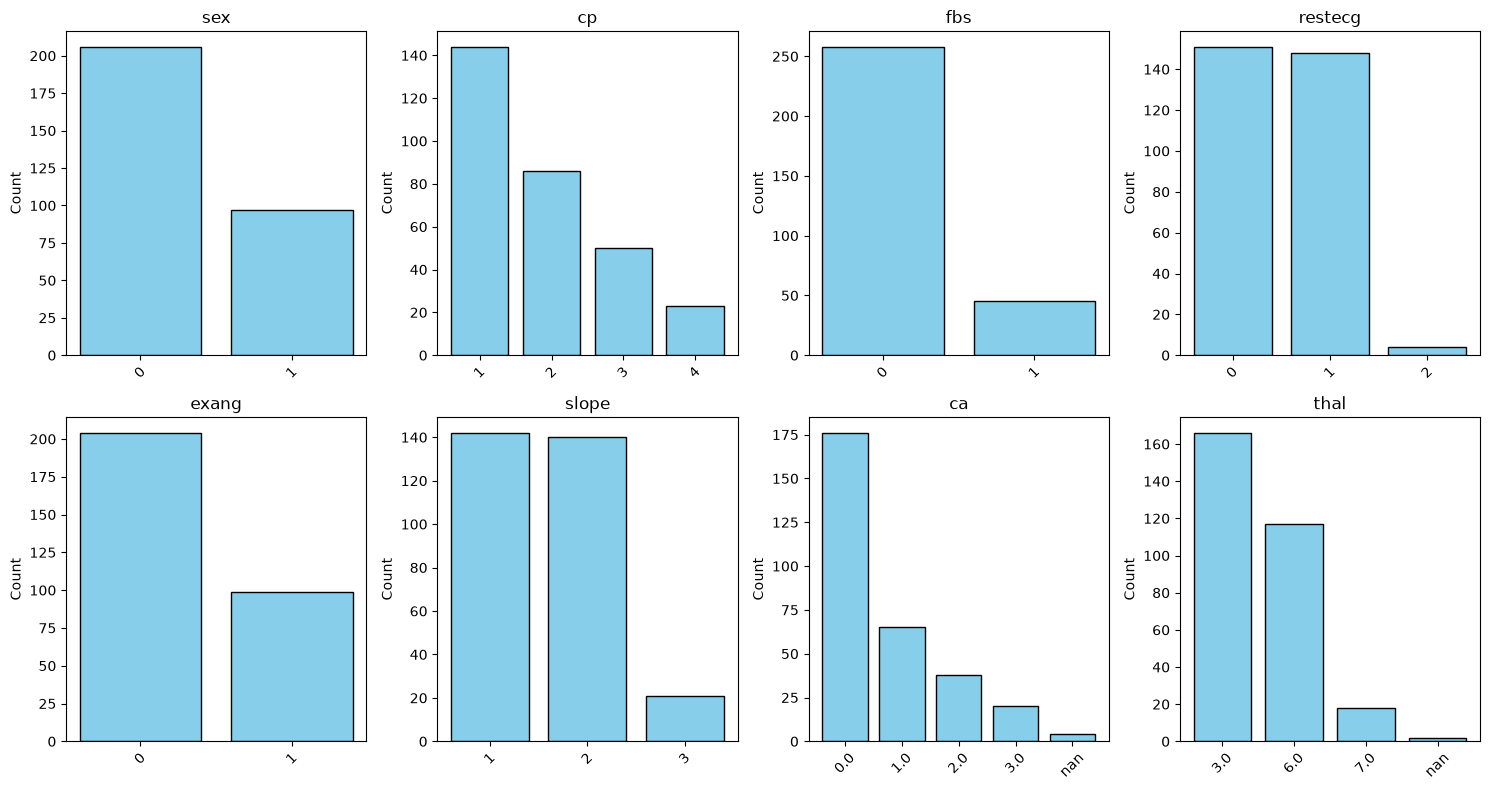

In [140]:
fig, axes = plt.subplots(2, 4, figsize=(15,8))
axes = axes.flatten()

for i, col in enumerate(X_cat.columns):
    counts = X_cat[col].value_counts(dropna=False)

    x_labels = sorted([str(x) for x in counts.index])

    axes[i].bar(x_labels, counts.values, color='skyblue', edgecolor='black')
    axes[i].set_title(f"{col}")
    axes[i].set_ylabel("Count")
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


None of the distibutions aren't evened out. It's not even close

### Numerical data

In [141]:
num_labels = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']

X_num = X[num_labels]

X_num

,age,trestbps,chol,thalach,oldpeak
0,63,145,233,150,2.3
1,67,160,286,108,1.5
2,67,120,229,129,2.6
3,37,130,250,187,3.5
4,41,130,204,172,1.4
...,...,...,...,...,...
298,45,110,264,132,1.2
299,68,144,193,141,3.4
300,57,130,131,115,1.2
301,57,130,236,174,0.0


In [142]:
X_num.describe()

,age,trestbps,chol,thalach,oldpeak
count,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.438944,131.689769,246.693069,149.607261,1.039604
std,9.038662,17.599748,51.776918,22.875003,1.161075
min,29.000000,94.000000,126.000000,71.000000,0.000000
25%,48.000000,120.000000,211.000000,133.500000,0.000000
50%,56.000000,130.000000,241.000000,153.000000,0.800000
75%,61.000000,140.000000,275.000000,166.000000,1.600000
max,77.000000,200.000000,564.000000,202.000000,6.200000


No missing values here

Small standard deviation relative to mean. Only exception is oldpeak where std is larger than its mean (data is spread).

Data not normalized

array([[<Axes: title={'center': 'age'}>,
        <Axes: title={'center': 'trestbps'}>],
       [<Axes: title={'center': 'chol'}>,
        <Axes: title={'center': 'thalach'}>],
       [<Axes: title={'center': 'oldpeak'}>, <Axes: >]], dtype=object)

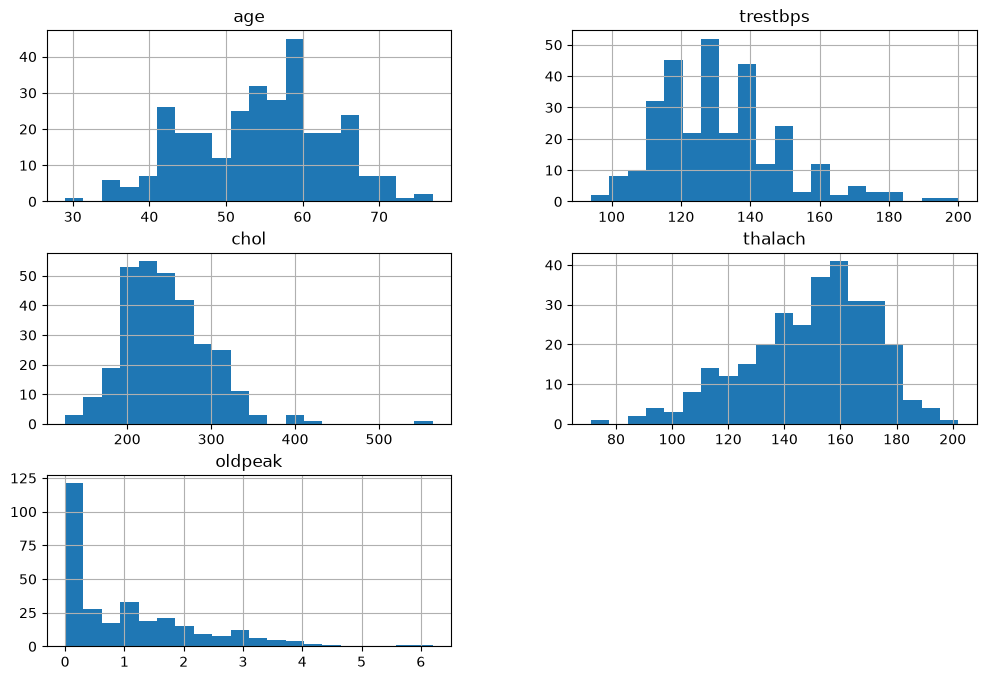

In [143]:
X_num.hist(bins=20, figsize=(12,8))

**age** does not resemble the normal distibution. There are multiple peaks on this histogram. 

**trestbps**, **chol** and **thalach** are some normal deistribution-esque. **chol** and **trestbps** are shifted to the left and **thalach** is shifted to the right.

**oldpeak** looks like exponential distribution. Might be worth to **log** it out.

<Axes: >

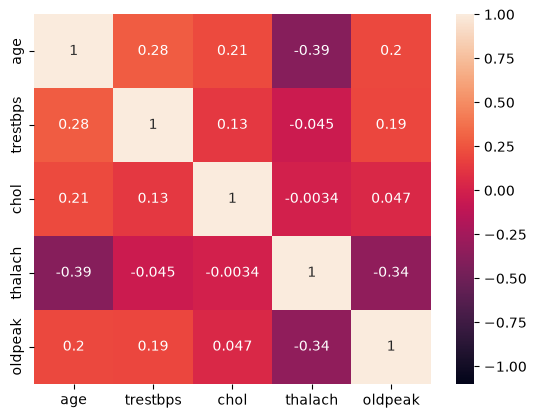

In [155]:
sns.heatmap(X_num.corr(), annot=True, vmin=1.0, vmax=-1.0)

**age** has big correlation values with other fields. 

What stands out is also the correlation between **thalach** and **oldpeak**

## Target analysis

In [ ]:
y: pd.DataFrame = heart_disease.data.targets

y

,num
0,0
1,2
2,1
3,0
4,0
...,...
298,1
299,2
300,3
301,1


In [ ]:
y.info()

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   num     303 non-null    int64
dtypes: int64(1)
memory usage: 2.5 KB


array([[<Axes: title={'center': 'num'}>]], dtype=object)

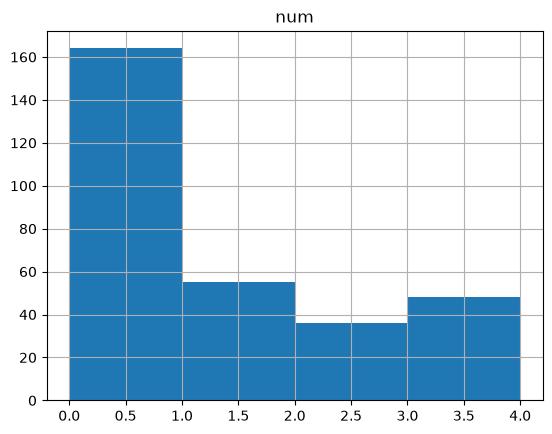

In [ ]:
y.hist(bins=4)

This is so not balanced. I migh have to duplicate the records.

In [153]:
X.corrwith(y.num)

age         0.222853
sex         0.224469
cp          0.407075
trestbps    0.157754
chol        0.070909
fbs         0.059186
restecg     0.183696
thalach    -0.415040
exang       0.397057
oldpeak     0.504092
slope       0.377957
ca          0.518909
thal        0.509923
dtype: float64

Huge correlations here. Especially with the **oldpeak**, **cp** and **exang**.

There are also less important ones. **fbs** and **chol** to be exact.